# Curvas de aprendizado — treino por épocas × one-shot

Para cada conjunto e binarização, um painel com:

- **curva azul**: acurácia de validação (com bleaching) a cada época da configuração de épocas **escolhida pela validação** — a mesma das tabelas do `summarize.py`. A época 0 é a primeira passada (classifica antes de gravar, penaliza e reforça). A curva segue até o early stopping parar;
- **ponto maior**: a melhor época, que é o modelo entregue; o teste dele e o do one-shot escolhido estão na segunda linha abaixo do título;
- **linha laranja tracejada**: validação do **one-shot escolhido** (o benchmark);
- **linha verde pontilhada**: validação do **one-shot com os mesmos bits e endereço** da configuração de épocas — isola o efeito do treino por épocas. Quando as duas configurações coincidem, as linhas se sobrepõem.

Os resultados vêm de `experiments/results/<conjunto>/<binarização>/seed<k>.jsonl` (gerados pelo `run_grid.py`). Conjuntos com o grid incompleto ficam de fora. O teste não participa de nenhuma escolha.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter

# the notebook lives in experiments/, but also works when started from the repository root
HERE = Path.cwd() if (Path.cwd() / "summarize.py").exists() else Path.cwd() / "experiments"
sys.path.insert(0, str(HERE))
import summarize as sm

RESULTS_DIR = HERE / "results"
FIGURES_DIR = HERE / "figures"
SEED = 0
SAVE_FIGURES = True  # PNGs in experiments/figures/
ENCODINGS = {"distributive": "Termômetro distributivo", "thermometer": "Termômetro comum"}

## Configuração escolhida e referências de cada painel

In [2]:
def epoch_key(r):
    return (r["bits"], r["address"], r["b"], r["rho0"], r["tau"])


def panel_record(dataset, encoding, rows):
    """chosen epoch configuration (same choice as summarize.py) and its one-shot references"""
    chosen = sm.choose(rows)
    if len(chosen) < len(sm.MODELS):  # incomplete grid
        return None
    cfg, ep_test, ep_val = chosen["epochs + bleaching"]
    row = next(r for r in rows if r["kind"] == "epochs"
               and epoch_key(r) == (cfg["bits"], cfg["address"], cfg["b"], cfg["rho0"], cfg["tau"]))
    os_cfg, os_test, os_val = chosen["one-shot + bleaching"]
    same = next(r for r in rows if r["kind"] == "oneshot"
                and r["bits"] == cfg["bits"] and r["address"] == cfg["address"])
    return dict(
        dataset=dataset, encoding=encoding,
        bits=cfg["bits"], address=cfg["address"], b=cfg["b"], rho0=cfg["rho0"], tau=cfg["tau"],
        best_epoch=row["bestEpoch"], epochs_run=len(row["accValPerEpoch"]), val_curve=row["accValPerEpoch"],
        epochs_val=ep_val["acc"], epochs_test=ep_test["acc"],
        oneshot_bits=os_cfg["bits"], oneshot_address=os_cfg["address"],
        oneshot_val=os_val["acc"], oneshot_test=os_test["acc"],
        same_val=same["bleaching"]["val"]["acc"], same_test=same["bleaching"]["test"]["acc"])


data = sm.load(str(RESULTS_DIR))
records = []
for (dataset, encoding), seeds in sorted(data.items()):
    if SEED in seeds and encoding in ENCODINGS:
        rec = panel_record(dataset, encoding, seeds[SEED])
        if rec is None:
            print("fora (grid incompleto): %s / %s" % (dataset, encoding))
        else:
            records.append(rec)
print("%d painéis (semente %d)" % (len(records), SEED))

fora (grid incompleto): jsc / thermometer
24 painéis (semente 0)


In [3]:
table = pd.DataFrame([{
    "conjunto": r["dataset"], "binarização": ENCODINGS[r["encoding"]],
    "épocas: teste (%)": 100 * r["epochs_test"], "one-shot: teste (%)": 100 * r["oneshot_test"],
    "Δ teste (pp)": 100 * (r["epochs_test"] - r["oneshot_test"]),
    "épocas: val (%)": 100 * r["epochs_val"], "one-shot: val (%)": 100 * r["oneshot_val"],
    "one-shot mesmos bits/end.: val (%)": 100 * r["same_val"],
    "melhor época": r["best_epoch"], "épocas rodadas": r["epochs_run"],
    "bits / end. (épocas)": "%d / %d" % (r["bits"], r["address"]),
    "b / ρ₀ / τ": "%d / %s / %s" % (r["b"], r["rho0"], r["tau"]),
    "bits / end. (one-shot)": "%d / %d" % (r["oneshot_bits"], r["oneshot_address"]),
} for r in records])
table.style.format(precision=2, decimal=",").hide(axis="index")

conjunto,binarização,épocas: teste (%),one-shot: teste (%),Δ teste (pp),épocas: val (%),one-shot: val (%),one-shot mesmos bits/end.: val (%),melhor época,épocas rodadas,bits / end. (épocas),b / ρ₀ / τ,bits / end. (one-shot)
australian,Termômetro distributivo,"83,65","79,81","3,85","88,35","86,41","84,47",2,6,4 / 4,1 / 0.8 / 0.05,8 / 12
australian,Termômetro comum,"79,81","83,65","-3,85","86,41","82,52","77,67",2,6,4 / 4,2 / 0.7 / 0.3,4 / 16
blood,Termômetro distributivo,"72,07","71,17","0,90","82,30","77,88","72,57",6,10,4 / 8,2 / 0.9 / 0.05,16 / 16
blood,Termômetro comum,"74,77","77,48","-2,70","84,96","81,42","77,88",5,9,16 / 12,2 / 0.7 / 0.5,16 / 20
christine,Termômetro distributivo,"69,29","69,90","-0,61","72,78","70,81","70,81",0,4,16 / 16,1 / 0.9 / 0.0,8 / 12
christine,Termômetro comum,"68,30","68,80","-0,49","71,55","70,57","70,57",0,4,16 / 24,1 / 0.7 / 0.1,16 / 24
higgs,Termômetro distributivo,"67,39","60,06","7,33","68,28","60,62","58,72",18,20,16 / 8,2 / 0.7 / 0.4,16 / 24
higgs,Termômetro comum,"62,12","59,34","2,77","62,45","58,94","57,52",7,11,16 / 4,1 / 0.1 / 0.5,8 / 12
iris,Termômetro distributivo,"100,00","100,00","0,00","100,00","100,00","100,00",0,4,4 / 4,1 / 0.1 / 0.0,4 / 4
iris,Termômetro comum,"95,24","95,24","0,00","100,00","100,00","100,00",0,4,4 / 4,1 / 0.1 / 0.0,4 / 4


## Gráficos interativos por bits da binarização

Para cada valor de bits escolhido no **dropdown**, cada painel mostra a melhor configuração **com aqueles bits**, com o mesmo critério do resto do notebook (melhor validação; empates: correção mais fraca, depois menor n-tupla):

- **curva azul**: validação por época da configuração de épocas escolhida entre n-tupla × b × ρ₀ × τ; o ponto maior é a melhor época;
- **laranja tracejada**: validação do one-shot escolhido entre as n-tuplas, com os mesmos bits;
- **verde pontilhada**: validação do one-shot com a mesma n-tupla da curva de épocas (mesma arquitetura).

O subtítulo de cada painel traz a configuração e o **teste** na melhor época. Passe o mouse para ver os valores; clique na legenda para esconder uma série. As figuras também são salvas como `.html` em `experiments/figures/`. A exibição carrega o plotly.js pela internet (CDN).

In [4]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from IPython.display import HTML, display


def choose_in_bits(rows, bits):
    """chosen epoch configuration and one-shot references among the configurations with these bits
    (best validation; ties: weakest correction, then smaller address — as summarize.choose)"""
    epochs = [r for r in rows if r["kind"] == "epochs" and r["bits"] == bits]
    oneshot = [r for r in rows if r["kind"] == "oneshot" and r["bits"] == bits]
    if not epochs or not oneshot:
        return None
    e = max(epochs, key=lambda r: (r["bleaching"]["val"]["acc"], -r["rho0"], -r["tau"], -r["b"], -r["address"]))
    o = max(oneshot, key=lambda r: (r["bleaching"]["val"]["acc"], -r["address"]))
    same = next((r for r in oneshot if r["address"] == e["address"]), None)
    return dict(
        bits=bits, address=e["address"], b=e["b"], rho0=e["rho0"], tau=e["tau"],
        best_epoch=e["bestEpoch"], val_curve=e["accValPerEpoch"],
        epochs_val=e["bleaching"]["val"]["acc"], epochs_test=e["bleaching"]["test"]["acc"],
        oneshot_address=o["address"], oneshot_val=o["bleaching"]["val"]["acc"], oneshot_test=o["bleaching"]["test"]["acc"],
        same_val=same["bleaching"]["val"]["acc"] if same else None, same_test=same["bleaching"]["test"]["acc"] if same else None)


# {(dataset, encoding): {bits: record}} for the datasets with a complete grid in this seed
bits_records = {}
for r in records:
    rows = data[(r["dataset"], r["encoding"])][SEED]
    per_bits = {b: choose_in_bits(rows, b) for b in sorted({row["bits"] for row in rows})}
    bits_records[(r["dataset"], r["encoding"])] = {b: rec for b, rec in per_bits.items() if rec}

# reference palette: categorical slots 1-3 and chart chrome (light surface)
SERIES = {"epochs": "#2a78d6", "oneshot": "#eb6834", "same": "#1baf7a"}
CHROME = dict(primary="#0b0b0b", secondary="#52514e", muted="#898781",
              grid="#e1e0d9", axis="#c3c2b7", surface="#fcfcfb")
PANEL_HEIGHT, TOP_MARGIN = 300, 170  # px; the title, the dropdown and the legend live in the top margin


def pt(value, decimals=1):
    return ("%.*f" % (decimals, value)).replace(".", ",")


def short(value):
    return pt(value, 2).rstrip("0").rstrip(",")


def panel_caption(dataset, rec, bits):
    if rec is None:
        return "<b>%s</b><br><span style='font-size:11px;color:%s'>sem configurações com %d bits</span>" % (
            dataset, CHROME["muted"], bits)
    return ("<b>%s</b><br><span style='font-size:11px;color:%s'>n-tupla %d · b %d · ρ₀ %s · τ %s<br>"
            "teste: épocas %s · one-shot %s</span>") % (
        dataset, CHROME["secondary"], rec["address"], rec["b"], short(rec["rho0"]), short(rec["tau"]),
        pt(100 * rec["epochs_test"]), pt(100 * rec["oneshot_test"]))


def y_range(rec):
    """the curve and both references, with a margin; accuracy is never shown above 100"""
    if rec is None:
        return None
    values = [100 * v for v in rec["val_curve"]] + [100 * rec["oneshot_val"]]
    if rec["same_val"] is not None:
        values.append(100 * rec["same_val"])
    low, high = min(values), max(values)
    pad = max(0.4, 0.1 * (high - low))
    return [low - pad, min(high + pad, 100.1)]


def interactive_curves(encoding, ncols=4, default_bits=None):
    """small multiples of one encoding, with a dropdown that chooses the bits of the binarization"""
    datasets = sorted(d for d, e in bits_records if e == encoding)
    if not datasets:
        return None
    bits_values = sorted({b for d in datasets for b in bits_records[(d, encoding)]})
    default_bits = default_bits if default_bits in bits_values else bits_values[-1]
    nrows = -(-len(datasets) // ncols)
    fig = make_subplots(rows=nrows, cols=ncols, horizontal_spacing=0.05, vertical_spacing=0.12 if nrows > 2 else 0.18)

    trace_bits = []
    for i, dataset in enumerate(datasets):
        row, col = i // ncols + 1, i % ncols + 1
        for bits, rec in bits_records[(dataset, encoding)].items():
            y = [100 * v for v in rec["val_curve"]]
            x = list(range(len(y)))
            span = [-0.3, max(len(y) - 0.7, 3.3)]
            best = rec["best_epoch"]
            lines = []
            if rec["same_val"] is not None:
                lines.append(dict(name="one-shot com a mesma n-tupla — validação", group="same", y=100 * rec["same_val"],
                                  dash="dot", hover="one-shot, n-tupla %d: %%{y:.2f}%%" % rec["address"]))
            lines.append(dict(name="one-shot escolhido — validação", group="oneshot", y=100 * rec["oneshot_val"],
                              dash="dash", hover="one-shot escolhido (n-tupla %d): %%{y:.2f}%%" % rec["oneshot_address"]))
            for line in lines:
                fig.add_trace(go.Scatter(x=span, y=[line["y"]] * 2, mode="lines", name=line["name"],
                                         legendgroup=line["group"], showlegend=(i == 0),
                                         line=dict(color=SERIES[line["group"]], width=1.6, dash=line["dash"]),
                                         hovertemplate=line["hover"] + "<extra></extra>", visible=(bits == default_bits)),
                              row=row, col=col)
                trace_bits.append(bits)
            fig.add_trace(go.Scatter(x=x, y=y, mode="lines+markers", name="treino por épocas — validação por época",
                                     legendgroup="epochs", showlegend=(i == 0),
                                     line=dict(color=SERIES["epochs"], width=2),
                                     marker=dict(size=7, color=SERIES["epochs"], line=dict(color=CHROME["surface"], width=1.5)),
                                     hovertemplate="época %{x}: %{y:.2f}%<extra></extra>", visible=(bits == default_bits)),
                          row=row, col=col)
            trace_bits.append(bits)
            fig.add_trace(go.Scatter(x=[best], y=[y[best]], mode="markers", name="melhor época (modelo entregue)",
                                     legendgroup="best", showlegend=(i == 0), cliponaxis=False,
                                     marker=dict(size=13, color=SERIES["epochs"], line=dict(color=CHROME["surface"], width=2)),
                                     hovertemplate=("melhor época %%{x}: validação %%{y:.2f}%%<br>teste: épocas %s%% · one-shot %s%%<extra></extra>"
                                                    % (pt(100 * rec["epochs_test"], 2), pt(100 * rec["oneshot_test"], 2))),
                                     visible=(bits == default_bits)), row=row, col=col)
            trace_bits.append(bits)

    def axis_name(i, letter):
        return "%saxis%s" % (letter, "" if i == 0 else i + 1)

    def layout_for(bits):
        """panel captions and y ranges of one choice of bits"""
        label = dict(text="bits da binarização", x=0.0, y=1 + 108 / (PANEL_HEIGHT * nrows), xref="paper", yref="paper",
                     xanchor="left", yanchor="bottom", showarrow=False, font=dict(size=11, color=CHROME["muted"]))
        captions = [label]
        ranges = {}
        for i, d in enumerate(datasets):
            rec = bits_records[(d, encoding)].get(bits)
            captions.append(dict(text=panel_caption(d, rec, bits), x=fig.layout[axis_name(i, "x")].domain[0],
                                 y=fig.layout[axis_name(i, "y")].domain[1], xref="paper", yref="paper",
                                 xanchor="left", yanchor="bottom", yshift=6, showarrow=False, align="left",
                                 font=dict(size=13, color=CHROME["primary"])))
            if rec is not None:
                ranges["%s.range" % axis_name(i, "y")] = y_range(rec)
        return dict(annotations=captions, **ranges)

    title = "%s — validação por época, treino por épocas × one-shot (semente %d)" % (ENCODINGS[encoding], SEED)
    buttons = [dict(label="%d bits" % bits, method="update",
                    args=[{"visible": [b == bits for b in trace_bits]},
                          dict({"title.text": "%s — %d bits" % (title, bits)}, **layout_for(bits))])
               for bits in bits_values]
    height = PANEL_HEIGHT * nrows + TOP_MARGIN + 50
    controls_y = 1 + 80 / (PANEL_HEIGHT * nrows)  # 80 px above the plot area, in paper coordinates
    fig.update_layout(
        title=dict(text="%s — %d bits" % (title, default_bits), x=0.01, xanchor="left",
                   y=1 - 14 / height, yanchor="top", font=dict(size=16, color=CHROME["primary"])),
        updatemenus=[dict(buttons=buttons, direction="down", active=bits_values.index(default_bits), showactive=True,
                          x=0.0, xanchor="left", y=controls_y, yanchor="middle", pad=dict(t=0, b=0),
                          bgcolor=CHROME["surface"], bordercolor=CHROME["axis"], font=dict(color=CHROME["primary"]))],
        legend=dict(orientation="h", x=0.11, xanchor="left", y=controls_y, yanchor="middle", font=dict(color=CHROME["primary"])),
        height=height, margin=dict(l=60, r=20, t=TOP_MARGIN, b=50),
        paper_bgcolor=CHROME["surface"], plot_bgcolor=CHROME["surface"], separators=",.",
        font=dict(family="system-ui, -apple-system, 'Segoe UI', sans-serif", size=12, color=CHROME["secondary"]),
        hovermode="closest",
        hoverlabel=dict(bgcolor="white", bordercolor=CHROME["axis"], font=dict(color=CHROME["primary"])))
    fig.update_layout(**layout_for(default_bits))
    fig.update_xaxes(dtick=1 if max(len(r["val_curve"]) for d in datasets for r in bits_records[(d, encoding)].values()) <= 12 else 2,
                     showgrid=False, linecolor=CHROME["axis"], ticks="outside", tickcolor=CHROME["axis"],
                     tickfont=dict(color=CHROME["muted"]), zeroline=False)
    fig.update_yaxes(gridcolor=CHROME["grid"], linecolor=CHROME["axis"], zeroline=False, tickfont=dict(color=CHROME["muted"]))
    for r_ in range(1, nrows + 1):
        fig.update_yaxes(title_text="acurácia de validação (%)", row=r_, col=1)
    for c in range(1, ncols + 1):
        fig.update_xaxes(title_text="época", row=nrows, col=c)

    if SAVE_FIGURES:
        FIGURES_DIR.mkdir(parents=True, exist_ok=True)
        fig.write_html(FIGURES_DIR / ("learning_curves_%s_seed%d.html" % (encoding, SEED)), include_plotlyjs="cdn",
                       config={"displaylogo": False})
    display(HTML(fig.to_html(include_plotlyjs="cdn", full_html=False, config={"displaylogo": False})))
    return fig

In [5]:
interactive_curves("distributive");

In [6]:
interactive_curves("thermometer");

## Figuras — uma por binarização

In [7]:
# reference palette: categorical slots 1-3 and chart chrome (light surface)
EPOCHS_COLOR, ONESHOT_COLOR, SAME_COLOR = "#2a78d6", "#eb6834", "#1baf7a"
INK = dict(primary="#0b0b0b", secondary="#52514e", muted="#898781",
           grid="#e1e0d9", axis="#c3c2b7", surface="#fcfcfb")
plt.rcParams.update({
    "font.family": ["Segoe UI", "DejaVu Sans", "sans-serif"], "font.size": 9,
    "figure.facecolor": INK["surface"], "axes.facecolor": INK["surface"],
    "axes.edgecolor": INK["axis"], "axes.labelcolor": INK["secondary"],
    "xtick.color": INK["muted"], "ytick.color": INK["muted"], "text.color": INK["primary"],
})


def comma(value):
    return str(value).replace(".", ",")


DECIMAL_COMMA = FuncFormatter(lambda v, _: comma("%g" % v))

LEGEND = [
    Line2D([], [], color=EPOCHS_COLOR, lw=2, marker="o", ms=5, mec=INK["surface"], label="treino por épocas — validação por época"),
    Line2D([], [], color=EPOCHS_COLOR, lw=0, marker="o", ms=9, mec=INK["surface"], mew=2, label="melhor época (modelo entregue)"),
    Line2D([], [], color=ONESHOT_COLOR, lw=1.5, ls=(0, (4, 3)), label="one-shot escolhido — validação"),
    Line2D([], [], color=SAME_COLOR, lw=1.5, ls=(0, (1, 2)), label="one-shot com os mesmos bits e endereço — validação"),
]


def plot_panel(ax, r, title=None):
    y = 100 * np.asarray(r["val_curve"])
    x = np.arange(len(y))
    best = r["best_epoch"]
    ax.axhline(100 * r["same_val"], color=SAME_COLOR, lw=1.5, ls=(0, (1, 2)), zorder=2)
    ax.axhline(100 * r["oneshot_val"], color=ONESHOT_COLOR, lw=1.5, ls=(0, (4, 3)), zorder=2)
    ax.plot(x, y, color=EPOCHS_COLOR, lw=2, marker="o", ms=5, mec=INK["surface"], mew=1.5,
            solid_capstyle="round", solid_joinstyle="round", zorder=3)
    ax.plot([best], [y[best]], marker="o", ms=9, color=EPOCHS_COLOR, mec=INK["surface"], mew=2, zorder=4, clip_on=False)

    values = np.concatenate([y, [100 * r["oneshot_val"], 100 * r["same_val"]]])
    low, high = values.min(), values.max()
    pad = max(0.5, 0.15 * (high - low))
    top = high + pad if high + pad <= 100 else max(high, 100) + 0.3 * pad  # accuracy never above 100
    ax.set_ylim(low - pad, top)
    ax.set_yticks([t for t in ax.get_yticks() if low - pad <= t <= min(top, 100)])
    ax.yaxis.set_major_formatter(DECIMAL_COMMA)

    ax.set_xlim(-0.5, max(len(y) - 0.5, 3.5))
    ax.set_xticks(x if len(x) <= 10 else x[::2])
    ax.grid(axis="y", color=INK["grid"], lw=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.set_title(title or r["dataset"], loc="left", pad=30, fontsize=10, fontweight="semibold", color=INK["primary"])
    meta = "bits %d · end. %d · b %d · ρ₀ %s · τ %s\nteste na melhor época (%d): épocas %s · one-shot %s" % (
        r["bits"], r["address"], r["b"], comma(r["rho0"]), comma(r["tau"]), best,
        comma("%.1f" % (100 * r["epochs_test"])), comma("%.1f" % (100 * r["oneshot_test"])))
    ax.annotate(meta, xy=(0, 1), xycoords="axes fraction", xytext=(0, 4), textcoords="offset points",
                ha="left", va="bottom", fontsize=7.5, color=INK["secondary"], linespacing=1.35)


def plot_encoding(encoding, ncols=4):
    recs = [r for r in records if r["encoding"] == encoding]
    if not recs:
        return None
    nrows = -(-len(recs) // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.0 * ncols, 3.4 * nrows), squeeze=False)
    for ax, r in zip(axes.flat, recs):
        plot_panel(ax, r)
    for ax in axes.flat[len(recs):]:
        ax.set_visible(False)
    for ax in axes[:, 0]:
        ax.set_ylabel("acurácia de validação (%)")
    for ax in axes[-1, :]:
        ax.set_xlabel("época")
    fig.suptitle("%s — curva de validação do treino por épocas × one-shot (semente %d)" % (ENCODINGS[encoding], SEED),
                 x=0.01, ha="left", fontsize=12, fontweight="semibold")
    fig.legend(handles=LEGEND, loc="upper left", bbox_to_anchor=(0.01, 0.965), ncol=4, frameon=False, fontsize=8.5)
    fig.tight_layout(rect=(0, 0, 1, 0.93), h_pad=2.0)
    if SAVE_FIGURES:
        FIGURES_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(FIGURES_DIR / ("learning_curves_%s_seed%d.png" % (encoding, SEED)), dpi=200, facecolor=INK["surface"])
    return fig

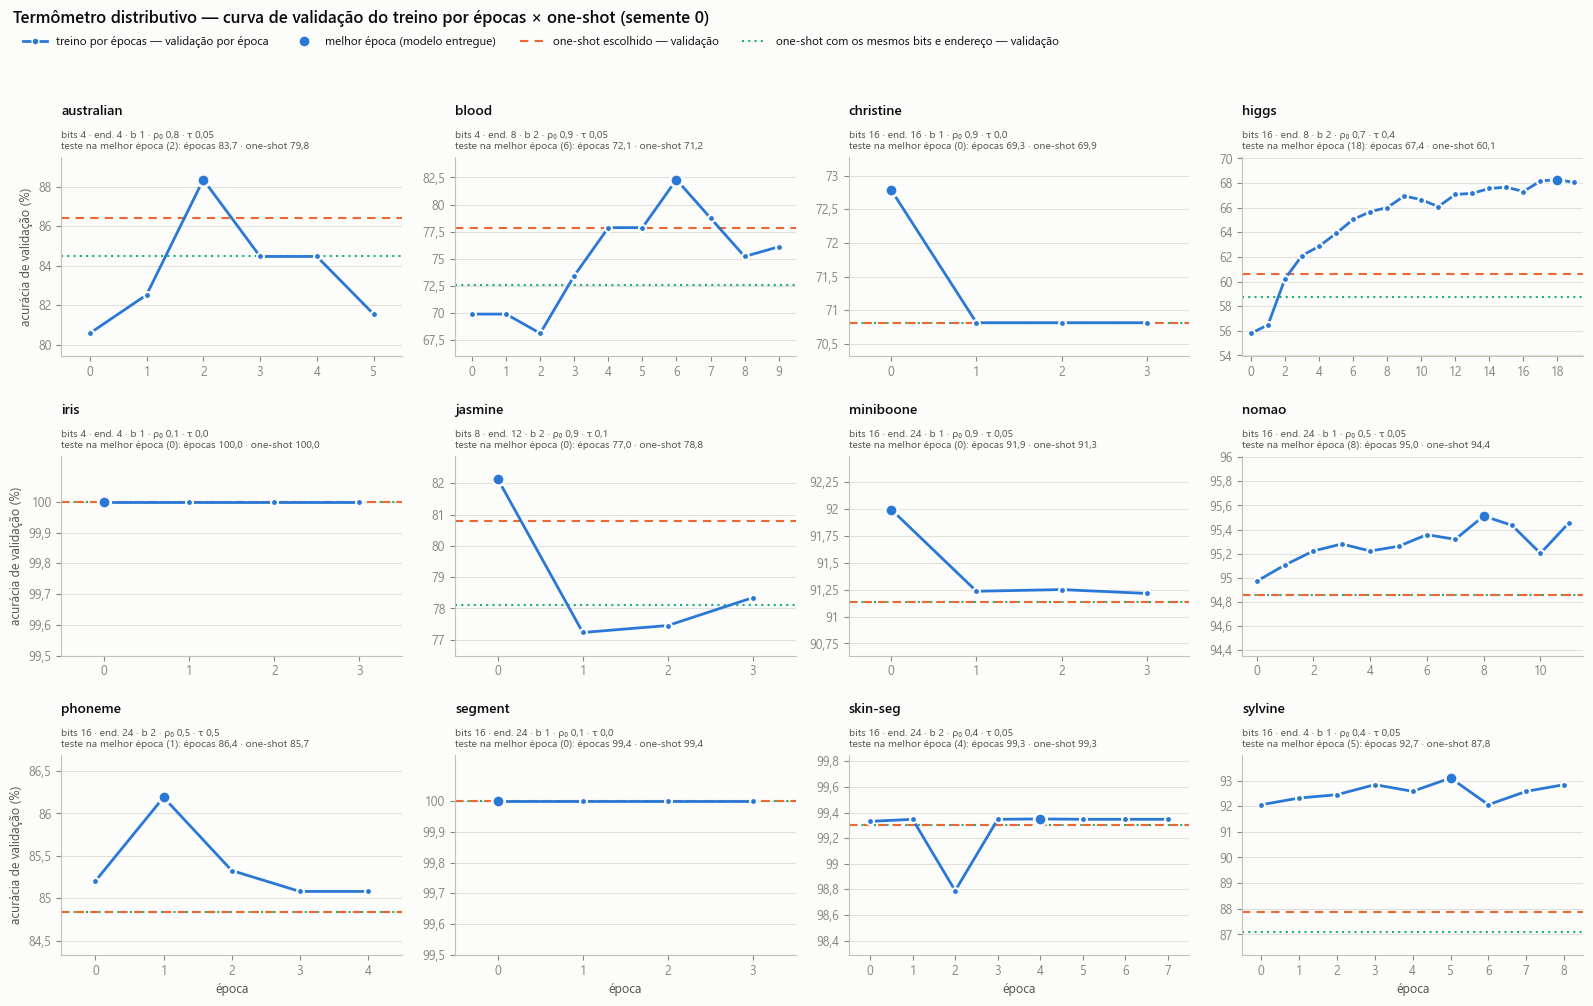

In [8]:
plot_encoding("distributive");

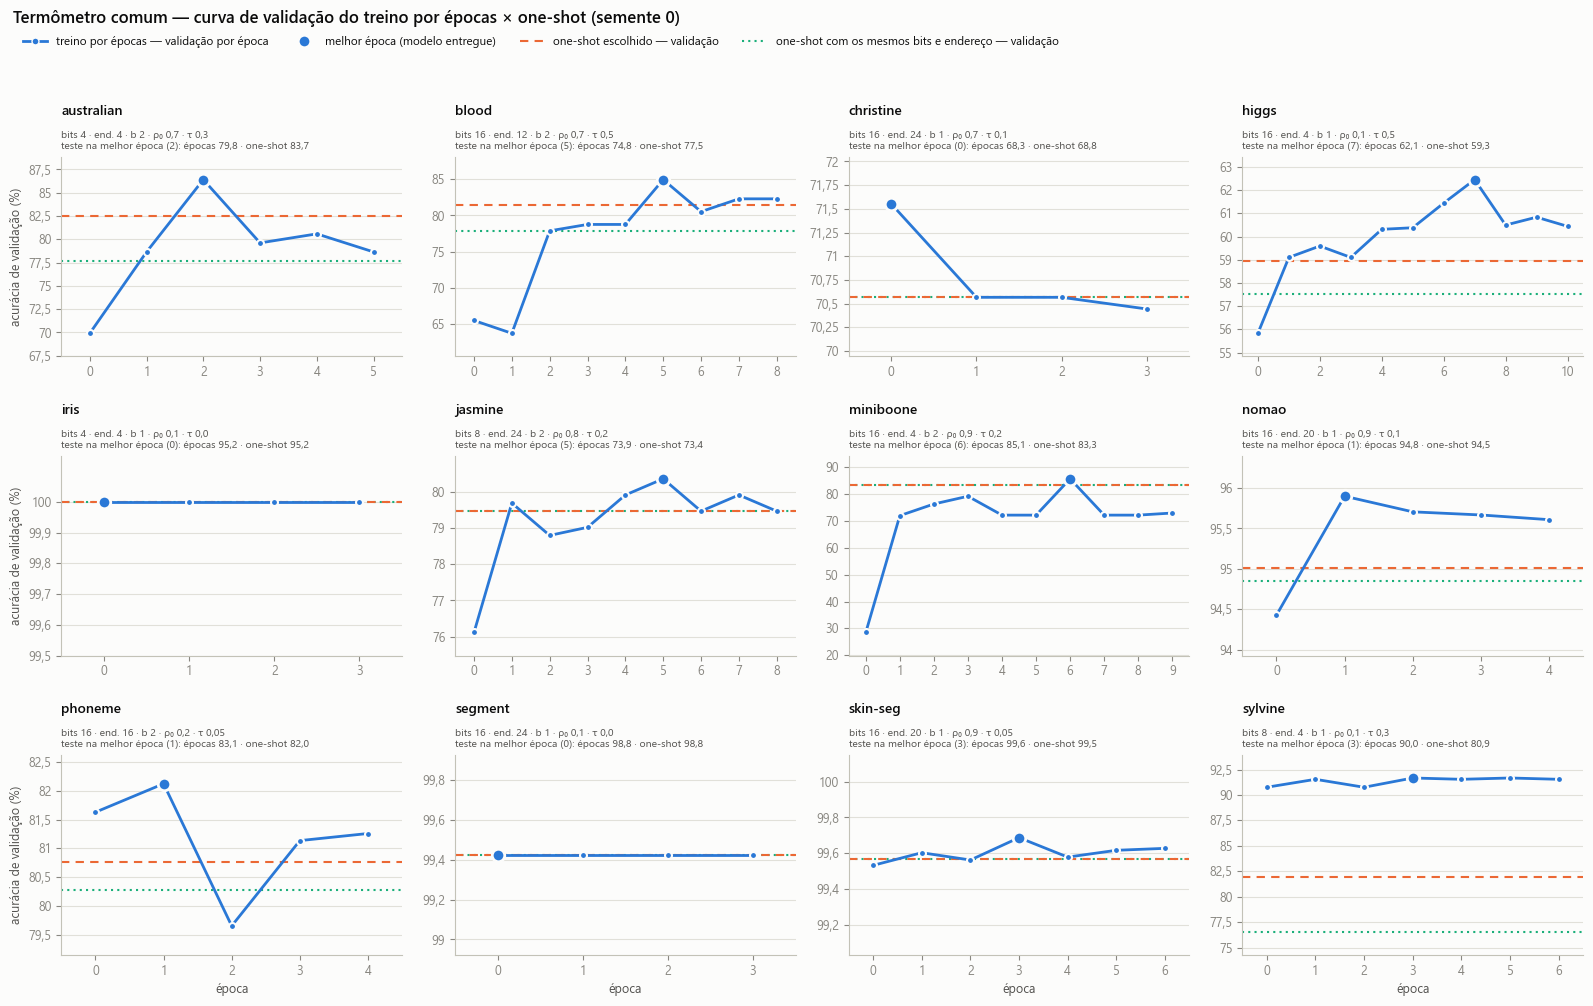

In [9]:
plot_encoding("thermometer");

## Um conjunto, as duas binarizações lado a lado

Troque o nome para ver outro conjunto (os nomes estão na tabela acima).

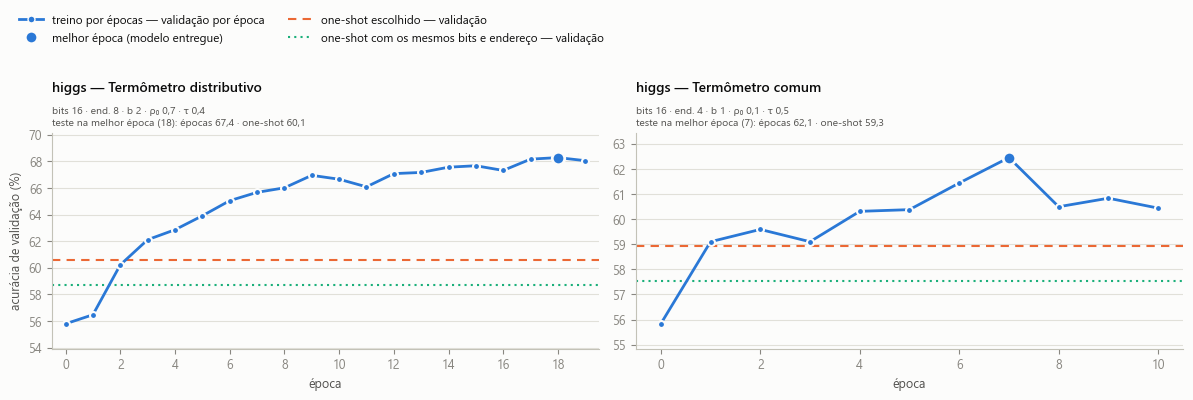

In [10]:
def plot_dataset(dataset):
    recs = {r["encoding"]: r for r in records if r["dataset"] == dataset}
    encodings = [e for e in ENCODINGS if e in recs]
    fig, axes = plt.subplots(1, len(encodings), figsize=(6.0 * len(encodings), 4.0), squeeze=False)
    for ax, encoding in zip(axes[0], encodings):
        plot_panel(ax, recs[encoding], title="%s — %s" % (dataset, ENCODINGS[encoding]))
        ax.set_xlabel("época")
    axes[0, 0].set_ylabel("acurácia de validação (%)")
    fig.legend(handles=LEGEND, loc="upper left", bbox_to_anchor=(0.01, 1.0), ncol=2, frameon=False, fontsize=8.5)
    fig.tight_layout(rect=(0, 0, 1, 0.84))
    return fig


plot_dataset("higgs");